# Ablation studies

Compare the baseline NumPy CNN with controlled changes to the architecture and
augmentation. Every variant uses the full CIFAR-10 training split and the same
training budget, batch size, optimizer, and random seed. Each trained variant
is evaluated on the complete official test split.

The layer implementations are loaded from notebook 03. This cell executes
only its layer-definition cells, not its training loop.

In [1]:
import gc
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import plotly.express as px
from tensorflow.keras.datasets import cifar10

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs" / "cifar10_baseline.json").is_file():
    PROJECT_ROOT = next(
        (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
         if (candidate / "configs" / "cifar10_baseline.json").is_file()),
        PROJECT_ROOT,
    )
if not (PROJECT_ROOT / "configs" / "cifar10_baseline.json").is_file():
    raise FileNotFoundError("Could not locate the repository root or baseline config")
CONFIG_PATH = PROJECT_ROOT / "configs" / "cifar10_baseline.json"
TRAINING_NOTEBOOK = PROJECT_ROOT / "notebooks" / "03_full_dataset_training.ipynb"

with CONFIG_PATH.open(encoding="utf-8") as file:
    config = json.load(file)

if not TRAINING_NOTEBOOK.is_file():
    raise FileNotFoundError(f"Training notebook not found: {TRAINING_NOTEBOOK}")

dataset_config = config["dataset"]
training_config = config["training"]
optimizer_config = training_config["optimizer"]
class_names = dataset_config["class_names"]
num_classes = dataset_config["num_classes"]
seed = config["project"]["seed"]

print("Project root:", PROJECT_ROOT)
print("Training notebook:", TRAINING_NOTEBOOK)
print("Training epochs per variant:", training_config["epochs"])

Project root: c:\Users\hp\Documents\GitHub\visual-feature-learning
Training notebook: c:\Users\hp\Documents\GitHub\visual-feature-learning\notebooks\03_full_dataset_training.ipynb
Training epochs per variant: 20


In [2]:
training_notebook = nbformat.read(TRAINING_NOTEBOOK, as_version=4)
code_cells = [
    cell.source
    for cell in training_notebook.cells
    if cell.cell_type == "code"
]


def find_definition_cell(required_markers):
    matches = [
        source
        for source in code_cells
        if all(marker in source for marker in required_markers)
    ]
    if len(matches) != 1:
        raise RuntimeError(
            "Could not uniquely find notebook 03 code cell containing: "
            + ", ".join(required_markers)
        )
    return matches[0]


layer_namespace = {
    "np": np,
    "num_classes": num_classes,
}

# Load the convolution primitives, then the remaining layer/model definitions.
conv_cell = find_definition_cell(
    ["def im2col_nchw(", "class Conv2D:"]
)
model_layer_cell = find_definition_cell(
    ["class CIFAR10CNN:", "class MaxPool2D:"]
)

exec(compile(conv_cell, str(TRAINING_NOTEBOOK), "exec"), layer_namespace)
exec(compile(model_layer_cell, str(TRAINING_NOTEBOOK), "exec"), layer_namespace)

Conv2D = layer_namespace["Conv2D"]
ReLU = layer_namespace["ReLU"]
MaxPool2D = layer_namespace["MaxPool2D"]
Dense = layer_namespace["Dense"]
cross_entropy_with_logits = layer_namespace["cross_entropy_with_logits"]

print("Loaded Conv2D, ReLU, MaxPool2D, Dense, and cross-entropy definitions.")

Loaded Conv2D, ReLU, MaxPool2D, Dense, and cross-entropy definitions.


In [3]:
# Remove float32 split arrays left in memory by earlier notebook versions.
for stale_name in ("x_train_nhwc", "x_test_nhwc", "x_train", "x_test"):
    globals().pop(stale_name, None)
gc.collect()

(train_images_raw, y_train_raw), (test_images_raw, y_test_raw) = cifar10.load_data()

y_train = y_train_raw.squeeze().astype(np.int64)
y_test = y_test_raw.squeeze().astype(np.int64)

assert train_images_raw.shape == (50000, 32, 32, 3)
assert test_images_raw.shape == (10000, 32, 32, 3)
assert train_images_raw.dtype == np.uint8
assert test_images_raw.dtype == np.uint8
assert y_train.shape == (50000,)
assert y_test.shape == (10000,)

normalization = dataset_config["normalization"]
mean = np.asarray(normalization["mean"], dtype=np.float32).reshape(1, 1, 1, 3)
std = np.asarray(normalization["std"], dtype=np.float32).reshape(1, 1, 1, 3)


def preprocess_batch(images):
    """Normalize a uint8 NHWC batch and return contiguous float32 NCHW."""
    images = np.asarray(images)
    if images.dtype != np.uint8:
        raise TypeError("Expected uint8 NHWC images")
    if images.ndim != 4 or images.shape[1:] != (32, 32, 3):
        raise ValueError("Expected images shaped (batch, 32, 32, 3)")
    images = images.astype(np.float32)
    images /= np.float32(255.0)
    images -= mean
    images /= std
    return np.ascontiguousarray(images.transpose(0, 3, 1, 2))


# Keep images in compact uint8 form and preprocess only active batches.
x_train = train_images_raw
x_test = test_images_raw
del train_images_raw, test_images_raw, y_train_raw, y_test_raw
gc.collect()
print("Full training set:", x_train.shape, y_train.shape, x_train.dtype)
print("Full test set:    ", x_test.shape, y_test.shape, x_test.dtype)
print("Images will be normalized one batch at a time.")

Full training set: (50000, 32, 32, 3) (50000,) uint8
Full test set:     (10000, 32, 32, 3) (10000,) uint8
Images will be normalized one batch at a time.


In [4]:
class AblationCNN:
    """Configurable one-stage or two-stage CNN for ablation experiments."""

    def __init__(
        self,
        rng,
        filters1=16,
        filters2=32,
        kernel_size=3,
        second_stage=True,
    ):
        self.second_stage = second_stage

        self.conv1 = Conv2D(3, filters1, kernel_size, rng, padding="same")
        self.relu1 = ReLU()
        self.pool1 = MaxPool2D(2, 2)

        if self.second_stage:
            self.conv2 = Conv2D(
                filters1,
                filters2,
                kernel_size,
                rng,
                padding="same",
            )
            self.relu2 = ReLU()
            self.pool2 = MaxPool2D(2, 2)
            dense_features = filters2 * 8 * 8
        else:
            dense_features = filters1 * 16 * 16

        self.dense = Dense(dense_features, num_classes, rng)

        layers = [self.conv1, self.dense]
        if self.second_stage:
            layers.append(self.conv2)

        for layer in layers:
            for attribute in (
                "weights",
                "bias",
                "velocity_weights",
                "velocity_bias",
            ):
                setattr(
                    layer,
                    attribute,
                    np.asarray(getattr(layer, attribute), dtype=np.float32),
                )

    def forward(self, x):
        x = np.asarray(x, dtype=np.float32)
        if x.ndim != 4 or x.shape[1:] != (3, 32, 32):
            raise ValueError("x must have shape (batch, 3, 32, 32)")

        x = self.conv1.forward(x)
        x = self.relu1.forward(x)
        x = self.pool1.forward(x)

        if self.second_stage:
            x = self.conv2.forward(x)
            x = self.relu2.forward(x)
            x = self.pool2.forward(x)

        self.flatten_shape = x.shape
        return self.dense.forward(x.reshape(x.shape[0], -1))

    def backward(self, d_logits):
        d_x, dense_weights, dense_bias = self.dense.backward(d_logits)
        d_x = d_x.reshape(self.flatten_shape)

        if self.second_stage:
            d_x = self.pool2.backward(d_x)
            d_x = self.relu2.backward(d_x)
            d_x, conv2_weights, conv2_bias = self.conv2.backward(d_x)

        d_x = self.pool1.backward(d_x)
        d_x = self.relu1.backward(d_x)
        _, conv1_weights, conv1_bias = self.conv1.backward(d_x)

        gradients = {
            "conv1": (conv1_weights, conv1_bias),
            "dense": (dense_weights, dense_bias),
        }
        if self.second_stage:
            gradients["conv2"] = (conv2_weights, conv2_bias)
        return gradients

    def update(self, gradients, learning_rate, momentum, weight_decay):
        self.conv1.update(
            *gradients["conv1"], learning_rate, momentum, weight_decay
        )
        if self.second_stage:
            self.conv2.update(
                *gradients["conv2"], learning_rate, momentum, weight_decay
            )
        self.dense.update(
            *gradients["dense"], learning_rate, momentum, weight_decay
        )

    def parameter_count(self):
        layers = [self.conv1]
        if self.second_stage:
            layers.append(self.conv2)
        layers.append(self.dense)
        return sum(layer.weights.size + layer.bias.size for layer in layers)

In [5]:
def train_one_epoch(
    model,
    x,
    y,
    batch_size,
    learning_rate,
    momentum,
    weight_decay,
    rng,
    horizontal_flip,
    log_every,
):
    order = rng.permutation(len(x))
    total_loss = 0.0
    total_correct = 0
    number_of_batches = (len(x) + batch_size - 1) // batch_size

    for batch_number, start in enumerate(range(0, len(x), batch_size), start=1):
        indices = order[start : start + batch_size]
        batch_x = x[indices].copy()
        batch_y = y[indices]

        if horizontal_flip:
            flip_mask = rng.random(len(batch_x)) < 0.5
            batch_x[flip_mask] = batch_x[flip_mask, :, ::-1, :]

        batch_x = preprocess_batch(batch_x)
        logits = model.forward(batch_x)
        loss, d_logits = cross_entropy_with_logits(logits, batch_y)
        gradients = model.backward(d_logits)
        model.update(
            gradients,
            learning_rate,
            momentum,
            weight_decay,
        )

        total_loss += loss * len(batch_y)
        total_correct += int(np.sum(logits.argmax(axis=1) == batch_y))

        if log_every and batch_number % log_every == 0:
            processed = min(start + len(batch_y), len(x))
            print(
                f"    batch {batch_number}/{number_of_batches} "
                f"- loss {total_loss / processed:.4f}"
            )

    return {
        "loss": total_loss / len(x),
        "accuracy": total_correct / len(x),
    }


def evaluate(model, x, y, batch_size):
    total_loss = 0.0
    total_correct = 0

    for start in range(0, len(x), batch_size):
        batch_x = preprocess_batch(x[start : start + batch_size])
        batch_y = y[start : start + batch_size]
        logits = model.forward(batch_x)
        loss, _ = cross_entropy_with_logits(logits.copy(), batch_y)

        total_loss += loss * len(batch_y)
        total_correct += int(np.sum(logits.argmax(axis=1) == batch_y))

    return {
        "loss": total_loss / len(x),
        "accuracy": total_correct / len(x),
    }


def save_ablation_checkpoint(model, path):
    arrays = {
        "conv1_weights": model.conv1.weights,
        "conv1_bias": model.conv1.bias,
        "dense_weights": model.dense.weights,
        "dense_bias": model.dense.bias,
    }
    if model.second_stage:
        arrays["conv2_weights"] = model.conv2.weights
        arrays["conv2_bias"] = model.conv2.bias
    np.savez(path, **arrays)

In [6]:
experiments = [
    {
        "name": "baseline",
        "filters1": 16,
        "filters2": 32,
        "kernel_size": 3,
        "second_stage": True,
        "horizontal_flip": True,
    },
    {
        "name": "without_second_stage",
        "filters1": 16,
        "filters2": 32,
        "kernel_size": 3,
        "second_stage": False,
        "horizontal_flip": True,
    },
    {
        "name": "narrow_channels",
        "filters1": 8,
        "filters2": 16,
        "kernel_size": 3,
        "second_stage": True,
        "horizontal_flip": True,
    },
    {
        "name": "larger_5x5_kernels",
        "filters1": 16,
        "filters2": 32,
        "kernel_size": 5,
        "second_stage": True,
        "horizontal_flip": True,
    },
    {
        "name": "without_horizontal_flip",
        "filters1": 16,
        "filters2": 32,
        "kernel_size": 3,
        "second_stage": True,
        "horizontal_flip": False,
    },
]

epochs = 10
# A small batch limits im2col/backprop temporary memory.
batch_size = min(training_config["batch_size"], 4)
learning_rate_start = optimizer_config["learning_rate"]
momentum = optimizer_config["momentum"]
weight_decay = optimizer_config["weight_decay"]
log_every = training_config["log_every_n_batches"]

schedule = training_config["learning_rate_schedule"]
milestones = set(schedule["milestones"])
gamma = schedule["gamma"]

output_dir = PROJECT_ROOT / "outputs" / "ablation_studies"
checkpoint_dir = output_dir / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print(f"Variants: {len(experiments)}")
print(f"Images per training epoch per variant: {len(x_train):,}")
print(f"Epochs per variant: {epochs}")
print(f"Expected training runs: {len(experiments) * epochs} full epochs")

Variants: 5
Images per training epoch per variant: 50,000
Epochs per variant: 10
Expected training runs: 50 full epochs


In [7]:
results = []

for experiment_number, experiment in enumerate(experiments, start=1):
    experiment_seed = seed
    rng = np.random.default_rng(experiment_seed)

    model = AblationCNN(
        rng=rng,
        filters1=experiment["filters1"],
        filters2=experiment["filters2"],
        kernel_size=experiment["kernel_size"],
        second_stage=experiment["second_stage"],
    )

    learning_rate = learning_rate_start
    history = {
        "epoch": [],
        "train_loss": [],
        "train_accuracy": [],
        "learning_rate": [],
    }

    print(
        f"\n[{experiment_number}/{len(experiments)}] "
        f"{experiment['name']} — "
        f"{model.parameter_count():,} parameters"
    )
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        train_result = train_one_epoch(
            model=model,
            x=x_train,
            y=y_train,
            batch_size=batch_size,
            learning_rate=learning_rate,
            momentum=momentum,
            weight_decay=weight_decay,
            rng=rng,
            horizontal_flip=experiment["horizontal_flip"],
            log_every=log_every,
        )

        history["epoch"].append(epoch)
        history["train_loss"].append(train_result["loss"])
        history["train_accuracy"].append(train_result["accuracy"])
        history["learning_rate"].append(learning_rate)

        print(
            f"  epoch {epoch:02d}/{epochs} | "
            f"loss {train_result['loss']:.4f} | "
            f"accuracy {train_result['accuracy']:.2%} | "
            f"lr {learning_rate:g}"
        )

        if epoch in milestones:
            learning_rate *= gamma

    test_result = evaluate(model, x_test, y_test, batch_size)
    elapsed_seconds = time.time() - start_time

    checkpoint_path = checkpoint_dir / f"{experiment['name']}.npz"
    save_ablation_checkpoint(model, checkpoint_path)

    result = {
        **experiment,
        "epochs": epochs,
        "parameter_count": model.parameter_count(),
        "train_loss_last": history["train_loss"][-1],
        "train_accuracy_last": history["train_accuracy"][-1],
        "test_loss": test_result["loss"],
        "test_accuracy": test_result["accuracy"],
        "training_seconds": elapsed_seconds,
        "history": history,
    }
    results.append(result)

    print(
        f"  test accuracy {test_result['accuracy']:.2%} | "
        f"elapsed {elapsed_seconds / 60:.1f} min"
    )

    with (output_dir / "results.json").open("w", encoding="utf-8") as file:
        json.dump(results, file, indent=2)

print("\nAll ablation experiments finished.")


[1/5] baseline — 25,578 parameters
    batch 100/12500 - loss 2.5147
    batch 200/12500 - loss 2.3981
    batch 300/12500 - loss 2.3576
    batch 400/12500 - loss 2.3302
    batch 500/12500 - loss 2.3087
    batch 600/12500 - loss 2.2739
    batch 700/12500 - loss 2.2481
    batch 800/12500 - loss 2.2262
    batch 900/12500 - loss 2.1983
    batch 1000/12500 - loss 2.1814
    batch 1100/12500 - loss 2.1756
    batch 1200/12500 - loss 2.1672
    batch 1300/12500 - loss 2.1540
    batch 1400/12500 - loss 2.1372
    batch 1500/12500 - loss 2.1197
    batch 1600/12500 - loss 2.1115
    batch 1700/12500 - loss 2.1021
    batch 1800/12500 - loss 2.0948
    batch 1900/12500 - loss 2.0875
    batch 2000/12500 - loss 2.0773
    batch 2100/12500 - loss 2.0676
    batch 2200/12500 - loss 2.0596
    batch 2300/12500 - loss 2.0566
    batch 2400/12500 - loss 2.0475
    batch 2500/12500 - loss 2.0453
    batch 2600/12500 - loss 2.0437
    batch 2700/12500 - loss 2.0388
    batch 2800/12500 - loss 

In [8]:
results_df = pd.DataFrame(
    [
        {
            "experiment": result["name"],
            "test_accuracy": result["test_accuracy"],
            "test_loss": result["test_loss"],
            "parameters": result["parameter_count"],
            "training_minutes": result["training_seconds"] / 60,
        }
        for result in results
    ]
).sort_values("test_accuracy", ascending=False)

results_df

,experiment,test_accuracy,test_loss,parameters,training_minutes
4,without_horizontal_flip,0.3494,1.829222,25578,53.635702
3,larger_5x5_kernels,0.3264,1.860203,34538,66.752581
2,narrow_channels,0.3168,1.904523,11642,41.659538
0,baseline,0.3156,2.056631,25578,58.089138
1,without_second_stage,0.1000,2.306631,41418,35.022268


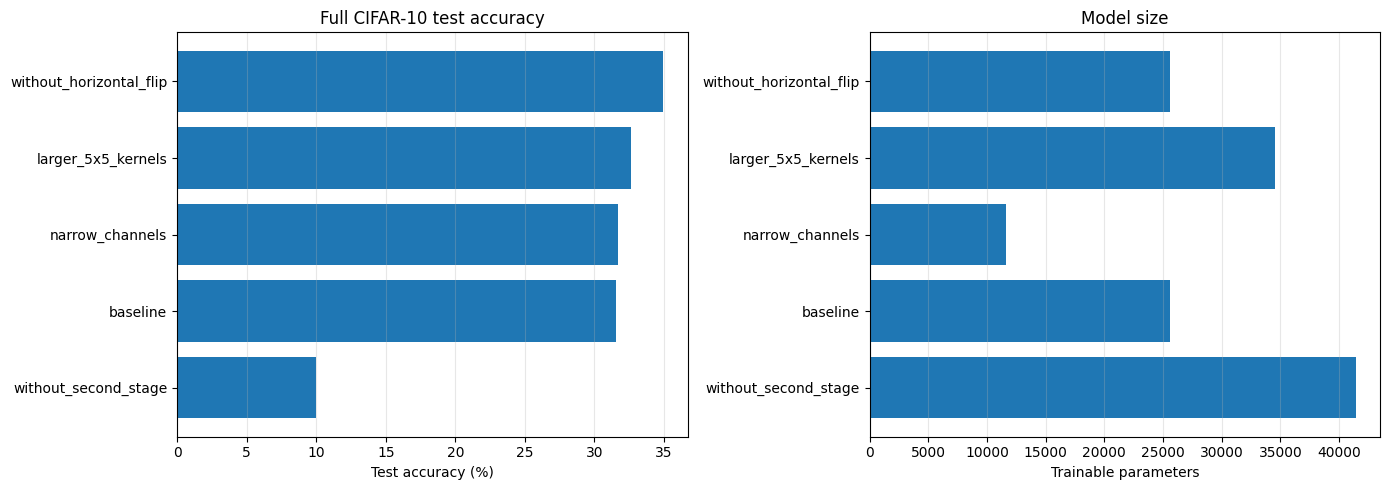

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ordered = results_df.sort_values("test_accuracy", ascending=True)
axes[0].barh(ordered["experiment"], ordered["test_accuracy"] * 100)
axes[0].set_xlabel("Test accuracy (%)")
axes[0].set_title("Full CIFAR-10 test accuracy")
axes[0].grid(axis="x", alpha=0.3)

axes[1].barh(ordered["experiment"], ordered["parameters"])
axes[1].set_xlabel("Trainable parameters")
axes[1].set_title("Model size")
axes[1].grid(axis="x", alpha=0.3)

fig.tight_layout()
plt.show()

In [10]:
fig = px.scatter_3d(
    results_df,
    x="parameters",
    y="test_accuracy",
    z="training_minutes",
    color="test_accuracy",
    hover_name="experiment",
    hover_data={
        "parameters": True,
        "test_accuracy": ":.2%",
        "training_minutes": ":.1f",
    },
    color_continuous_scale="Viridis",
    title="Ablation trade-offs: accuracy, parameter count, and training time",
    labels={
        "parameters": "Trainable parameters",
        "test_accuracy": "Test accuracy",
        "training_minutes": "Training time (minutes)",
    },
)
fig.update_layout(height=700)
fig.show()

In [11]:
csv_path = output_dir / "results.csv"
results_df.to_csv(csv_path, index=False)

print("Saved detailed experiment histories to:", output_dir / "results.json")
print("Saved comparison table to:", csv_path)

Saved detailed experiment histories to: c:\Users\hp\Documents\GitHub\visual-feature-learning\outputs\ablation_studies\results.json
Saved comparison table to: c:\Users\hp\Documents\GitHub\visual-feature-learning\outputs\ablation_studies\results.csv
